# Week 11 Lab Work

**Dataset:** Adult / Census Income (UCI Machine Learning Repository)

1. Load the same pre-processed dataset as the last lab works.
2. Scale the features and take a fixed random sample.
3. Apply Single, Complete and Average linkage and draw a dendrogram for each.
4. Cut each tree into 2 clusters and compare them.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

cols = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]


def get_file(data_filename):
    for base in [".", ".."]:
        if not os.path.isdir(base):
            continue
        for root, dirs, files in os.walk(base):
            if data_filename in files:
                return os.path.join(root, data_filename)

    print(f"'{data_filename}' not found in the workspace. Downloading it dynamically...")
    url = f"https://archive.ics.uci.edu/ml/machine-learning-databases/adult/{data_filename}"
    urllib.request.urlretrieve(url, data_filename)
    return data_filename


# 1. Load and pre-process the data
path = get_file("adult.data")
print(f"Loading data from: {path}")
df = pd.read_csv(path, header=None, names=cols, skipinitialspace=True, na_values="?")
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["income"] = (df["income"] == ">50K").astype(int)
df = pd.get_dummies(df, drop_first=True)

print("Shape:", df.shape)
print("Missing cells:", df.isnull().sum().sum())
df.head()


Loading data from: ./adult.data
Shape: (30139, 97)
Missing cells: 0


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,77516,13,2174,0,40,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,83311,13,0,0,13,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,38,215646,9,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
3,53,234721,7,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
4,28,338409,13,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,False,False,False


## 2. Scale the features and sample the rows

`MinMaxScaler` is used instead of `StandardScaler` because a rare one-hot column would otherwise be scaled to a huge value and turn one row into an outlier for every method; with `MinMaxScaler` the one-hot columns stay 0 or 1 and the numeric columns go to 0-1.

Hierarchical linkage needs a full pairwise distance matrix. For about 30,000 rows this is several GB and will hang, so a fixed random sample of 2000 rows (`random_state=42`) is used. `income` is kept out of the features and is used only to check the clusters.

In [2]:
sample = df.sample(n=2000, random_state=42)
X = MinMaxScaler().fit_transform(sample.drop(columns=["income"]))
y = sample["income"].to_numpy()
print("Sample shape:", X.shape)
print("Income share in sample:", y.mean().round(4))


Sample shape: (2000, 96)
Income share in sample: 0.253


## 3. Single, Complete and Average linkage

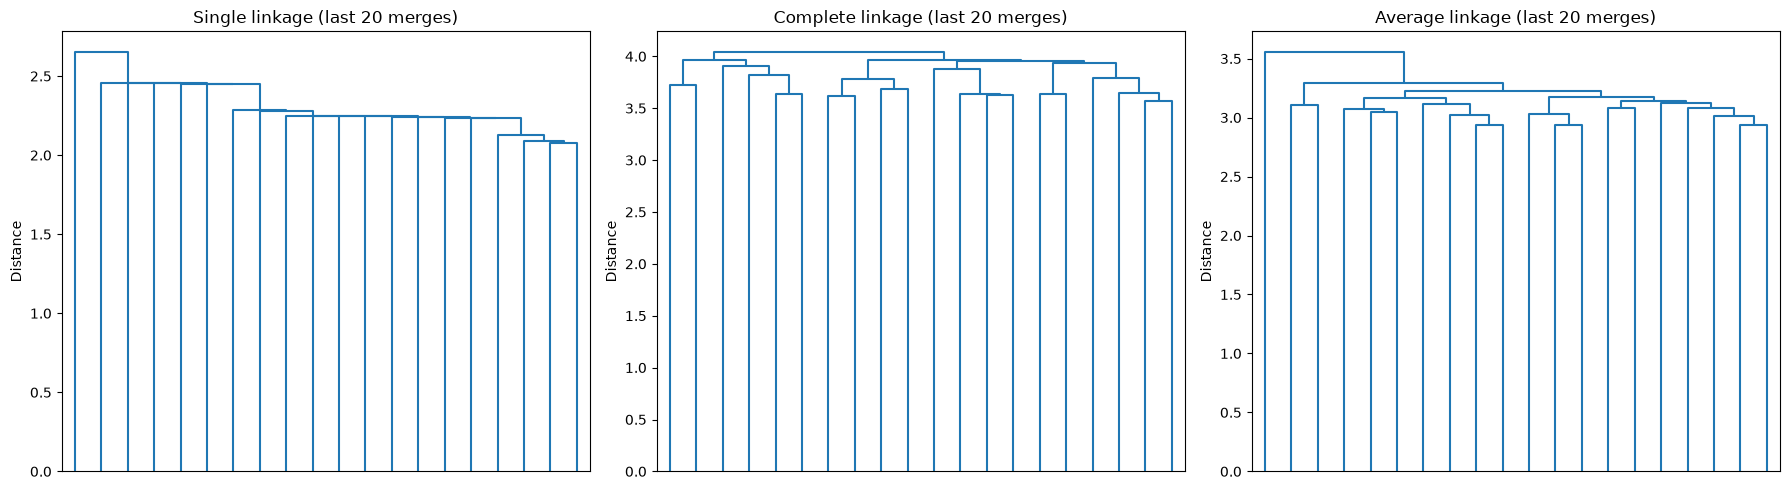

In [3]:
methods = ["single", "complete", "average"]
trees = {m: linkage(X, method=m, metric="euclidean") for m in methods}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, m in zip(axes, methods):
    dendrogram(trees[m], truncate_mode="lastp", p=20, ax=ax, no_labels=True)
    ax.set_title(f"{m.capitalize()} linkage (last 20 merges)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()


## 4. Cut into 2 clusters and compare

In [4]:
rows = []
for m in methods:
    labels = fcluster(trees[m], t=2, criterion="maxclust")
    sizes = np.bincount(labels)[1:]
    purity = sum(np.bincount(y[labels == c]).max() for c in np.unique(labels)) / len(y)
    rows.append({"Method": m.capitalize(), "Cluster sizes": sizes.tolist(),
                 "Silhouette": round(silhouette_score(X, labels), 4),
                 "Purity vs income": round(purity, 4)})
print(pd.DataFrame(rows).to_string(index=False))
print("Majority-class baseline:", round(max(y.mean(), 1 - y.mean()), 4))


  Method Cluster sizes  Silhouette  Purity vs income
  Single     [1999, 1]      0.2425             0.747
Complete   [247, 1753]      0.0671             0.747
 Average     [1999, 1]      0.2425             0.747
Majority-class baseline: 0.747


Single and Average linkage still cut off one point at 2 clusters. The same trees are cut again into 5 clusters to see how the methods differ.

In [5]:
for m in methods:
    labels = fcluster(trees[m], t=5, criterion="maxclust")
    print(m.capitalize(), sorted(np.bincount(labels)[1:].tolist(), reverse=True))


Single [1996, 1, 1, 1, 1]
Complete [985, 446, 322, 142, 105]
Average [1941, 47, 6, 5, 1]


## 5. Conclusions

| Method | Cluster sizes (k=2) | Silhouette | Purity vs income | Cluster sizes (k=5) |
|---|---|---|---|---|
| Single | [1999, 1] | 0.2425 | 0.747 | [1996, 1, 1, 1, 1] |
| Complete | [247, 1753] | 0.0671 | 0.747 | [985, 446, 322, 142, 105] |
| Average | [1999, 1] | 0.2425 | 0.747 | [1941, 47, 6, 5, 1] |

- **Single linkage** chains: it gives one giant cluster (1999 rows) and one lone point at k=2, and [1996, 1, 1, 1, 1] at k=5. It peels off outliers one by one.
- **Complete linkage** gives the most balanced clusters: [247, 1753] at k=2 and [985, 446, 322, 142, 105] at k=5. Its silhouette (0.0671) is the lowest, but it is the only method that finds real groups.
- **Average linkage** sits between the two. It also cuts one point at k=2, but at k=5 it finds a few more small groups ([1941, 47, 6, 5, 1]).
- The silhouette of Single and Average (0.2425) is higher only because they cut off one outlier. Purity is 0.747 for every method, the same as always guessing the majority class (0.747), so none of the clusters separate `income`.
